# Курс Data Science. Дипломный проект. Задача классификации.
## «Модель прогнозирования остановки на питстоп в чемпионате автогонок в классе "Формула1"»

## 3. Построение предсказательных моделей и оценка их качества.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import ensemble
from sklearn import linear_model

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
#отключим оповещения
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Загрузим очищенные данные из CSV-файла
df_mm = pd.read_csv('data/cleaned_data.csv')
df_mm.head(2)

,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,Normalized_TyreLife,...,Race_United States Grand Prix,Race_Chinese Grand Prix,Race_Emilia Romagna Grand Prix,Race_French Grand Prix,Race_Pre-Season Test,Race_Pre-Season Track Session,Year_2023.0,Year_2024.0,Year_2025.0,Year_2022.0
0,0.000000,0.0,0.012987,0.842105,0.156287,0.513789,0.582499,0.0,0.0,0.106188,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.012987,0.0,0.025974,0.894737,0.123438,0.496101,0.567511,0.0,0.0,0.165775,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


Выделяем целевую переменную. Разделяем датасет на тестовую и тренировочную части.

In [3]:
target_col = 'PitNextLap'

X = df_mm.drop(['PitNextLap'], axis=1)
y=df_mm[target_col].astype(int).to_numpy()

print('Размер матрицы переменных : ', X.shape)
print('Размер таргета: ', y.shape)

Размер матрицы переменных :  (101371, 83)
Размер таргета:  (101371,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Размер train data:", X_train.shape, y_train.shape)
print("Размер test data:", X_test.shape, y_test.shape)

Размер train data: (81096, 83) (81096,)
Размер test data: (20275, 83) (20275,)


### 3.1 LogisticRegression

Создаем объект класса LogisticRegression, обучаем на наших данных и смотрим метрики.

In [5]:
# Смотрим метрики при параметрах по умолчанию.
log_reg = linear_model.LogisticRegression( 
    class_weight='balanced'
)
#Обучаем модель
log_reg.fit(X_train, y_train)
y_test_pred = log_reg.predict(X_test)

#Рассчитываем accuracy
print('Accuracy на тестовом наборе: {:.2f}'.format(metrics.accuracy_score(y_test, y_test_pred)))
#Рассчитываем precision
print('Precision на тестовом наборе: {:.2f}'.format(metrics.precision_score(y_test, y_test_pred)))
#Рассчитываем recall
print('Recall на тестовом наборе: {:.2f}'.format(metrics.recall_score(y_test, y_test_pred)))
#Рассчитываем F1-меру
print('F1 score на тестовом наборе: {:.2f}'.format(metrics.f1_score(y_test, y_test_pred)))
print('Total 1 class predicted: {:.2f}'.format(y_test_pred.sum()))

Accuracy на тестовом наборе: 0.83
Precision на тестовом наборе: 0.13
Recall на тестовом наборе: 0.84
F1 score на тестовом наборе: 0.22
Total 1 class predicted: 3895.00


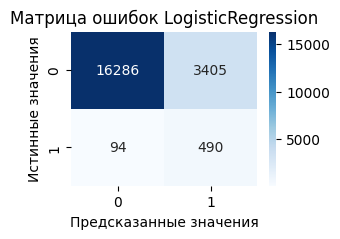

In [6]:
cm = metrics.confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(3, 2))
# Создаём тепловую карту
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

# Подписи осей и заголовок
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('Матрица ошибок LogisticRegression')
plt.show()

Будем ориентироваться в основном на метрику F1, так как это сбалансированная оценка, а также потому, что предсказываемые классы сильно несбалансированы. По метрикам и матрице ошибок видно, чтоLogisticRegression с параматрами по умолчанию показывает довольно скромные результаты по предсказанию классов.

### 3.2 RandomForestClassifier

Создаем объект класса RandomForestClassifier, обучаем на наших данных и смотрим метрики. Задаем параметры, чтобы заранее избежать переобучение.

In [7]:
#Создаем объект класса случайный лес
rf = ensemble.RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

#Обучаем модель
rf.fit(X_train, y_train)
#Выводим значения метрики 
y_train_pred = rf.predict(X_train)
print('f1-Train: {:.2f}'.format(metrics.f1_score(y_train, y_train_pred)))
y_test_pred = rf.predict(X_test)

#Рассчитываем accuracy
print('Accuracy на тестовом наборе: {:.2f}'.format(metrics.accuracy_score(y_test, y_test_pred)))
#Рассчитываем precision
print('Precision на тестовом наборе: {:.2f}'.format(metrics.precision_score(y_test, y_test_pred)))
#Рассчитываем recall
print('Recall на тестовом наборе: {:.2f}'.format(metrics.recall_score(y_test, y_test_pred)))
#Рассчитываем F1-меру
print('F1 score на тестовом наборе: {:.2f}'.format(metrics.f1_score(y_test, y_test_pred)))
print('Total 1 class predicted: {:.2f}'.format(y_test_pred.sum()))

f1-Train: 0.34
Accuracy на тестовом наборе: 0.89
Precision на тестовом наборе: 0.19
Recall на тестовом наборе: 0.85
F1 score на тестовом наборе: 0.31
Total 1 class predicted: 2619.00


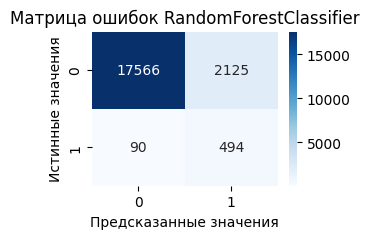

In [8]:
cm = metrics.confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(3, 2))
# Создаём тепловую карту
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

# Подписи осей и заголовок
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('Матрица ошибок RandomForestClassifier')
plt.show()

RandomForestClassifier также демонстрирует скромный результат по метрике F1 и матрице ошибок, хотя он и лучше, чем у предыдущей модели.

### 3.3 LGBMClassifier

Создаем объект класса LGBMClassifier, обучаем на наших данных и смотрим метрики.

In [9]:
lgbm_base = LGBMClassifier(n_jobs=-1, verbose=-1, class_weight= "balanced")
#Обучаем модель
lgbm_base.fit(X_train, y_train)

y_test_pred = lgbm_base.predict(X_test)

#Рассчитываем accuracy
print('Accuracy на тестовом наборе: {:.2f}'.format(metrics.accuracy_score(y_test, y_test_pred)))
#Рассчитываем precision
print('Precision на тестовом наборе: {:.2f}'.format(metrics.precision_score(y_test, y_test_pred)))
#Рассчитываем recall
print('Recall на тестовом наборе: {:.2f}'.format(metrics.recall_score(y_test, y_test_pred)))
#Рассчитываем F1-меру
print('F1 score на тестовом наборе: {:.2f}'.format(metrics.f1_score(y_test, y_test_pred)))
print('Total 1 class predicted: {:.2f}'.format(y_test_pred.sum()))

Accuracy на тестовом наборе: 0.97
Precision на тестовом наборе: 0.45
Recall на тестовом наборе: 0.94
F1 score на тестовом наборе: 0.61
Total 1 class predicted: 1220.00


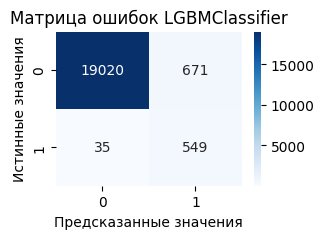

In [10]:
cm = metrics.confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(3, 2))
# Создаём тепловую карту
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
#plt.figure(figsize=(6, 4))
# Подписи осей и заголовок
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('Матрица ошибок LGBMClassifier')
plt.show()

Классификатор LGBMClassifier показывает существенно лучший результат по сравнению с первыми двумя классификаторами. Также он позволяет сделать оценку важности признаков.

In [11]:
# Получаем оценки
importances = lgbm_base.feature_importances_

# Создаём Series для удобного отображения имен признаков
feature_importance_df = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

print(feature_importance_df[:15])

LapTime (s)                  622
RemainingLaps                198
Normalized_TyreLife          163
TyreLife                     130
LapNumber                    115
TyreLifeRemainingRatio       114
Stint_TyreLife               103
LapTime_Delta                 89
Position                      79
LapDelta_TyreLife             78
PositionTyreLife              74
Cumulative_Degradation        70
Position_Change               63
Year_2023.0                   53
Race_Singapore Grand Prix     53
dtype: int32


### 3.4 XGBClassifier

Для классификатора XGBClassifier был произведен поиск гиперпараметров при помощи инструмента GridSearchCV, поскольку поиск занял 4 часа, закомментировал эти ячейки.

In [12]:
"""
from sklearn.model_selection import GridSearchCV

# Определение сетки параметров
param_grid = {
    'n_estimators': [1400, 1500, 1600],
    'max_depth': [7, 8, 9],
    'learning_rate': [0.2, 0.3, 0.4],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    "min_child_weight": [3],
    "reg_alpha": [0.1],
    "reg_lambda": [1.0],
    "objective": ['binary:logistic'],
    "eval_metric": ["auc"],
    "tree_method": ["hist"]
}
"""

'\nfrom sklearn.model_selection import GridSearchCV\n\n# Определение сетки параметров\nparam_grid = {\n    \'n_estimators\': [1400, 1500, 1600],\n    \'max_depth\': [7, 8, 9],\n    \'learning_rate\': [0.2, 0.3, 0.4],\n    \'subsample\': [0.7, 0.8, 0.9],\n    \'colsample_bytree\': [0.7, 0.8, 0.9],\n    "min_child_weight": [3],\n    "reg_alpha": [0.1],\n    "reg_lambda": [1.0],\n    "objective": [\'binary:logistic\'],\n    "eval_metric": ["auc"],\n    "tree_method": ["hist"]\n}\n'

In [13]:
"""
# Создание модели и поиск
xgb_base = XGBClassifier()
grid_search = GridSearchCV(xgb_base, param_grid, cv=5, scoring='accuracy', n_jobs = -1, verbose=1)
grid_search.fit(X_train, y_train)

# Лучшие параметры и оценка
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший результат:", grid_search.best_score_)
"""

'\n# Создание модели и поиск\nxgb_base = XGBClassifier()\ngrid_search = GridSearchCV(xgb_base, param_grid, cv=5, scoring=\'accuracy\', n_jobs = -1, verbose=1)\ngrid_search.fit(X_train, y_train)\n\n# Лучшие параметры и оценка\nprint("Лучшие параметры:", grid_search.best_params_)\nprint("Лучший результат:", grid_search.best_score_)\n'

Запускаем XGBClassifier с подобранными параметрами.

In [14]:
xgb_base = XGBClassifier(
    n_estimators = 400,
    max_depth = 7,
    learning_rate = 0.2,
    subsample = 0.9,
    colsample_bytree =0.9,
    min_child_weight = 3,
    reg_alpha = 0.1,
    reg_lambda = 1.0,
    objective = 'binary:logistic',
    eval_metric = "auc",
    tree_method = "hist"
    )

#Обучаем модель
xgb_base.fit(X_train, y_train)
y_test_pred = xgb_base.predict(X_test)

#Рассчитываем accuracy
print('Accuracy на тестовом наборе: {:.2f}'.format(metrics.accuracy_score(y_test, y_test_pred)))
#Рассчитываем precision
print('Precision на тестовом наборе: {:.2f}'.format(metrics.precision_score(y_test, y_test_pred)))
#Рассчитываем recall
print('Recall на тестовом наборе: {:.2f}'.format(metrics.recall_score(y_test, y_test_pred)))
#Рассчитываем F1-меру
print('F1 score на тестовом наборе: {:.2f}'.format(metrics.f1_score(y_test, y_test_pred)))
print('Total 1 class predicted: {:.2f}'.format(y_test_pred.sum()))

Accuracy на тестовом наборе: 0.99
Precision на тестовом наборе: 0.90
Recall на тестовом наборе: 0.73
F1 score на тестовом наборе: 0.80
Total 1 class predicted: 475.00


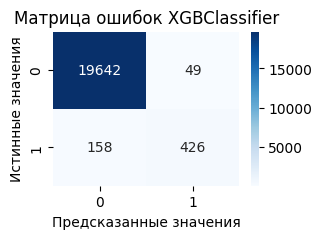

In [15]:
cm = metrics.confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(3, 2))
# Создаём тепловую карту
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
#plt.figure(figsize=(6, 4))
# Подписи осей и заголовок
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('Матрица ошибок XGBClassifier')
plt.show()

Видим, что удалось еще существенно улучшить результат по предсказанию, о чем говорят метрики и матрица ошибок.
Сохраним обученную модель в файл.

In [16]:
# Сохраненим эту модель в файл pickle
with open("web/app/models/best_model.pkl", "wb") as f:
    pickle.dump(xgb_base, f)

Попробуем также поискать оптимальный порог вероятности класса.

In [17]:
#Нас интересует только вероятность класса (второй столбец)
y_test_proba_pred = pd.Series(xgb_base.predict_proba(X_test)[:, 1])
#Создадим списки, в которых будем хранить значения метрик 
recall_scores = []
precision_scores = []
f1_scores = []
#Сгенерируем набор вероятностных порогов в диапазоне от 0.1 до 1
thresholds = np.arange(0.1, 1, 0.05)
#В цикле будем перебирать сгенерированные пороги
for threshold in thresholds:
    y_pred = y_test_proba_pred.apply(lambda x: 1 if x>threshold else 0)
    #Считаем метрики и добавляем их в списки
    recall_scores.append(metrics.recall_score(y_test, y_pred))
    precision_scores.append(metrics.precision_score(y_test, y_pred))
    f1_scores.append(metrics.f1_score(y_test, y_pred))

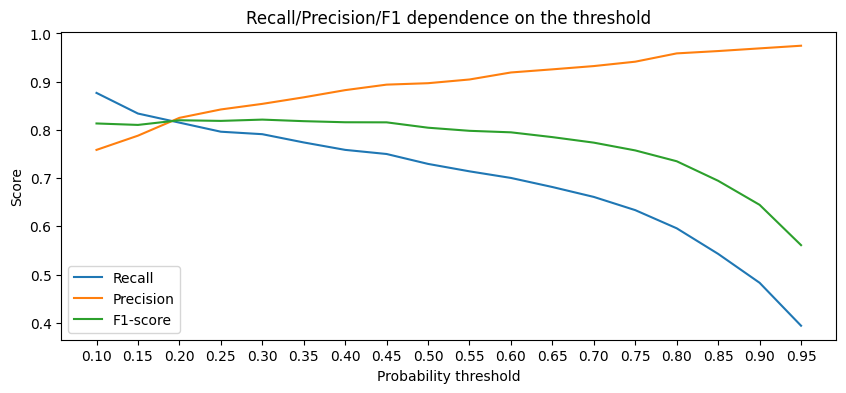

In [18]:
#Визуализируем метрики при различных threshold
fig, ax = plt.subplots(figsize=(10, 4)) #фигура + координатная плоскость
#Строим линейный график зависимости recall от threshold
ax.plot(thresholds, recall_scores, label='Recall')
#Строим линейный график зависимости precision от threshold
ax.plot(thresholds, precision_scores, label='Precision')
#Строим линейный график зависимости F1 от threshold
ax.plot(thresholds, f1_scores, label='F1-score')
 
#Даём графику название и подписываем оси
ax.set_title('Recall/Precision/F1 dependence on the threshold')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Score')
#Устанавливаем отметки по оси x
ax.set_xticks(thresholds) 
#Отображаем легенду
ax.legend();

Как можно видеть из графика выше, максимальное значение F1 метрики находится примерно в точке 0,19 порога вероятности.
Попробуем изменить порог при классификации и посмотрим результат.

In [19]:
#Задаём оптимальный порог вероятностей, полученный из графика
threshold_opt = 0.19

y_pred_opt = y_test_proba_pred.apply(lambda x: 1 if x > threshold_opt else 0)
#Считаем метрики
print(metrics.classification_report(y_test, y_pred_opt))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     19691
           1       0.82      0.82      0.82       584

    accuracy                           0.99     20275
   macro avg       0.91      0.91      0.91     20275
weighted avg       0.99      0.99      0.99     20275



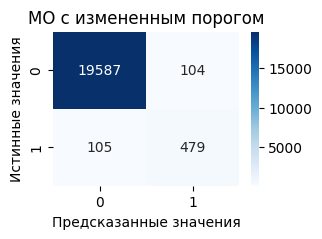

In [20]:
cm = metrics.confusion_matrix(y_test, y_pred_opt)
fig, ax = plt.subplots(figsize=(3, 2))
# Создаём тепловую карту
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
#plt.figure(figsize=(6, 4))
# Подписи осей и заголовок
plt.xlabel('Предсказанные значения')
plt.ylabel('Истинные значения')
plt.title('МО с измененным порогом')
plt.show()

Согласно метрикам и матрице ошибок, нам удалось еще немного улучшить результат предсказания.

### Краткие выводы по построению предсказательных моделей.

В это части дипломной работы мы проделали следующее:
* Загрузили из файла сохраненные предобработанные данные.
* Разделили их на тренировочную и тестовую части.
* Построили модель LogisticRegression.
* Построили модель RandomForestClassifier.
* Построили модель LGBMClassifier.
* Построили модель XGBClassifier.
* Произвели оценку предсказаний каждой модели, лучшую из них сохранили в файл.